## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Isaiah De Vera

**Date:** 10/19/2026

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

Q1


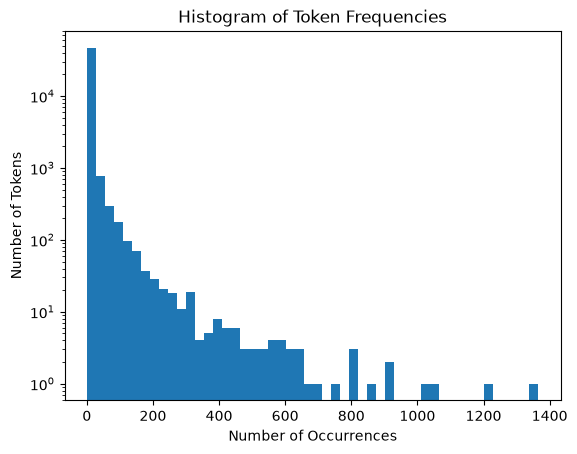

The histogram is very strongly skewed right. On a normal scale, the left bar was much higher than the right, so I made the y-axis a log scale. Most tokens only appear a couple times while some appear hundreds or thousands of times


In [3]:
# Your Phase 1 solution to the problem goes here.
print('Q1')

plt.hist(token_count.values(), bins=50)
plt.yscale('log')
plt.xlabel('Number of Occurrences')
plt.ylabel('Number of Tokens')
plt.title('Histogram of Token Frequencies')
plt.show()

print('The histogram is very strongly skewed right. On a normal scale, the left bar was much higher than the right, so I made the y-axis a log scale. Most tokens only appear a couple times while some appear hundreds or thousands of times')

In [4]:
print('Q2')

#1
df = pd.read_parquet('data/Phishing_clean.parquet', engine = 'fastparquet')
y = df['Email Type']
X = df.drop(columns = 'Email Type')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

#2
model = LinearRegression()
model.fit(X_train, y_train)
print('Training R^2:', model.score(X_train, y_train))
print('Test R^2:', model.score(X_test, y_test))

#3
coefficients = pd.Series(model.coef_, index=X.columns)
top = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(20)
 
print("\nTop 20 coefficients by absolute value:\n", top.to_string())


Q2
Training R^2: 0.7687875341139676
Test R^2: 0.655923984746692

Top 20 coefficients by absolute value:
 {text-decoration:    1.069928
background-image:   -0.896583
none;               -0.835839
localized            0.763722
{color:             -0.680250
thermal              0.652498
aging                0.650395
helvetica,           0.626287
cnet                -0.535749
group:               0.526756
xanaax               0.522954
inkjet              -0.522767
intervention        -0.497330
crawler              0.484388
arial,              -0.477392
girlfriend           0.477231
form.                0.445999
ï¿½ï¿½               0.441778
rhythm               0.432392
para                 0.427922


Q3


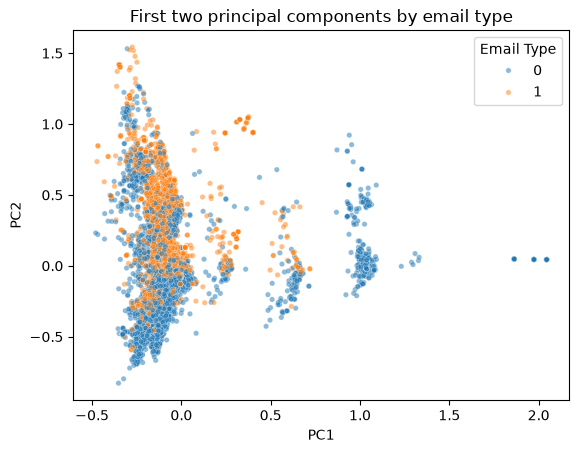

Along PC1, there are distinct vertical stripes at around -0.25, 0.2, 0.5 and 1. For PC1 above 1, they are all not a scam regardless of PC2. For other PC1 values, a higher PC2 above around 0 are scams, while PC2 below 0 are typically not a scam.


In [5]:
print('Q3')

pca = PCA(n_components=2)
Z = pca.fit_transform(X)

plot_df = pd.DataFrame(Z, columns=['PC1', 'PC2'], index=X.index)
plot_df['Email Type'] = y

sns.scatterplot(data=plot_df, x='PC1', y='PC2', hue='Email Type', alpha=0.5, s=15)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('First two principal components by email type')
plt.show()

print('Along PC1, there are distinct vertical stripes at around -0.25, 0.2, 0.5 and 1. For PC1 above 1, they are all not a scam regardless of PC2. For other PC1 values, a higher PC2 above around 0 are scams, while PC2 below 0 are typically not a scam.')

In [6]:
print('Q4')

pca = PCA(n_components=2610)
Z_train = pca.fit_transform(X_train)
Z_test = pca.transform(X_test)

model_pca = LinearRegression()
model_pca.fit(Z_train, y_train)

print('PCA Regression Training R^2:', model_pca.score(Z_train, y_train))
print('PCA Regression Test R^2:', model_pca.score(Z_test, y_test))

print('The results are very similar to the linear regression. This makes sense since using 2610 components is almost all of the 2711 tokens, so it retains almost all the variation of the total dataset.')

Q4
PCA Regression Training R^2: 0.7678719293227674
PCA Regression Test R^2: 0.6584780718049499
The results are very similar to the linear regression. This makes sense since using 2610 components is almost all of the 2711 tokens, so it retains almost all the variation of the total dataset.


In [7]:
print('Q5')

print('PCA is usefule for high dimensional regression since it simplifies multiple variables into a few principal components which can be easier to process and easier to interpret since there are less variables. ')

Q5
PCA is usefule for high dimensional regression since it simplifies multiple variables into a few principal components which can be easier to process and easier to interpret since there are less variables. 


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 95c58082828b97940c28675cf28e2e5fba32fe6e
- **AI tool and model used:** ChatGPT

### *Prompts used

1. **\*\*Q1.\*\***

**\*\*Tokens\*\***: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

import pickle\
\
with open('data/all_tokens.pickle', 'rb') as file:\
&#x20;   all_tokens = pickle.load(file)\
&#x20;   \
from collections import Counter\
token_count = Counter(all_tokens)\
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. \
What do you notice about the frequency of occurrence of different tokens? How does it look?

\# Your Phase 1 solution to the problem goes here.\
print('Q1')\
\
plt.hist(token_count.values(), bins=50)\
plt.yscale('log')\
plt.xlabel('Number of Occurrences')\
plt.ylabel('Number of Tokens')\
plt.title('Histogram of Token Frequencies')\
plt.show()\
\
print('The histogram is very strongly skewed right. On a normal scale, the left bar was much higher than the right, so I made the y-axis a log scale. Most tokens only appear a couple times while some appear hundreds or thousands of times')

2. **\*\*Q2.\*\***&#x20;

Load \`Phishing_clean.parquet\`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the \`Email Type\` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1\. Perform an 80/20 train-test split of the data.
2\. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3\. What words have the largest coefficients in absolute value and most strongly influence predictions?&#x20;

print('Q2')\
\
\#1\
df = pd.read_parquet('data/Phishing_clean.parquet', engine = 'fastparquet')\
y = df['Email Type']\
X = df.drop(columns = 'Email Type')\
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)\
\
\#2\
model = LinearRegression()\
model.fit(X_train, y_train)\
print('Training R^2:', model.score(X_train, y_train))\
print('Test R^2:', model.score(X_test, y_test))\
\
\#3\
coefficients = pd.Series(model.coef\_, index=X.columns)\
top = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(20)\
&#x20;\
print("\nTop 20 coefficients by absolute value:\n", top.to_string())\

3. **\*\*Q3.\*\***&#x20;

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, \`Email Type\`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

print('Q3')\
\
pca = PCA(n_components=2)\
Z = pca.fit_transform(X)\
\
plot_df = pd.DataFrame(Z, columns=['PC1', 'PC2'], index=X.index)\
plot_df['Email Type'] = y\
\
sns.scatterplot(data=plot_df, x='PC1', y='PC2', hue='Email Type', alpha=0.5, s=15)\
plt.xlabel('PC1')\
plt.ylabel('PC2')\
plt.title('First two principal components by email type')\
plt.show()\
\
print('Along PC1, there are distinct vertical stripes at around -0.25, 0.2, 0.5 and 1. For PC1 above 1, they are all not a scam regardless of PC2. For other PC1 values, a higher PC2 above around 0 are scams, while PC2 below 0 are typically not a scam.')

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Your code is correct for plotting the distribution of token frequencies. I would make the written observation a little more precise:
The histogram is strongly right-skewed. Most tokens occur only a few times, while a small number of tokens appear hundreds or even thousands of times. The distribution has a long right tail, meaning that very frequent tokens are much less common than rare tokens. I used a logarithmic scale on the y-axis to make it easier to see the differences among token frequencies.
2. Revised Q2 

print('Q2')

# 1. Load data and perform an 80/20 train-test split
df = pd.read_parquet('data/Phishing_clean.parquet', engine='fastparquet')

y = df['Email Type']
X = df.drop(columns='Email Type')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)

# 2. Fit linear regression and calculate R^2
model = LinearRegression()
model.fit(X_train, y_train)

print('Training R^2:', model.score(X_train, y_train))
print('Test R^2:', model.score(X_test, y_test))

# 3. Find the 20 largest coefficients by absolute value
coefficients = pd.Series(model.coef_, index=X.columns)

top = coefficients.loc[
    coefficients.abs().sort_values(ascending=False).index
].head(20)

print('\nTop 20 coefficients by absolute value:')
print(top.to_string())

3. I'd polish your interpretation slightly to make it more precise:
The scatter plot shows some separation between phishing and legitimate emails along the first two principal components. There are distinct vertical stripes along PC1, suggesting that many emails have similar values for this component. For PC1 values above approximately 1, most or all emails appear to be legitimate, regardless of PC2. At lower PC1 values, emails with PC2 above approximately 0 appear more likely to be phishing scams, while emails below 0 appear more likely to be legitimate. However, the two classes are not perfectly separated, so the first two principal components do not completely distinguish phishing emails from legitimate ones.

4. Your code prints the actual training and test \(R^2\) values, which you should include in your final answer when reporting the comparison.

5. Your answer is on the right track! I'd make it a little more precise by mentioning dimensionality reduction and reduced multicollinearity.
PCA is useful for high-dimensional regression because it reduces the number of predictors while retaining as much of the variation in the original data as possible. This can reduce computational costs, help address multicollinearity between correlated features, and potentially reduce overfitting. The resulting model uses fewer predictors, although the principal components can be harder to interpret than the original words.


### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | The AI response has the same ideas as my original, but rewrote it to be more grammatically clear |
| 2 | reject | the change was adding comments for what each part does, but the question describes what each part does already. it also changed how top was found but it had the same functionality and output |
| 3 | accept | The AI response again just cleaned up my original conclusion to be more precise
| 4 | accept | When making the comparison, I should have included the numbers, so the conclusion can see evidence that they are close
| 5 | accept | Dimensionality reduction and reduced multicollinearity are big benefits to PCA regression so I wanted to add more to include it

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

Q1


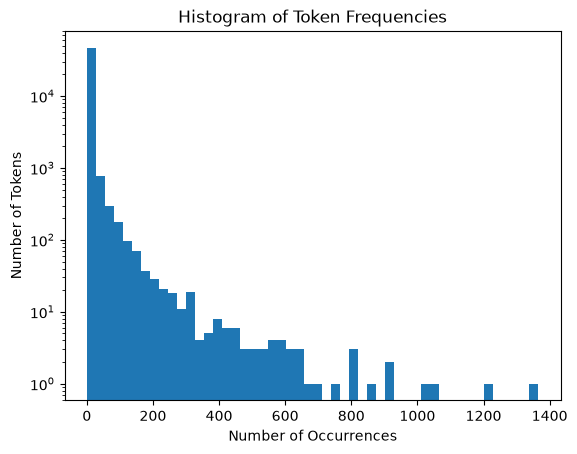

The histogram is strongly right-skewed. Most tokens occur only a few times, while a small number of tokens appear hundreds or even thousands of times. The distribution has a long right tail, meaning that very frequent tokens are much less common than rare tokens. I used a logarithmic scale on the y-axis to make it easier to see the differences among token frequencies.


In [8]:
# Your Phase 2 solution to the problem goes here.
print('Q1')

plt.hist(token_count.values(), bins=50)
plt.yscale('log')
plt.xlabel('Number of Occurrences')
plt.ylabel('Number of Tokens')
plt.title('Histogram of Token Frequencies')
plt.show()

print('The histogram is strongly right-skewed. Most tokens occur only a few times, while a small number of tokens appear hundreds or even thousands of times. The distribution has a long right tail, meaning that very frequent tokens are much less common than rare tokens. I used a logarithmic scale on the y-axis to make it easier to see the differences among token frequencies.')

In [9]:
print('Q2')

#1
df = pd.read_parquet('data/Phishing_clean.parquet', engine = 'fastparquet')
y = df['Email Type']
X = df.drop(columns = 'Email Type')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

#2
model = LinearRegression()
model.fit(X_train, y_train)
print('Training R^2:', model.score(X_train, y_train))
print('Test R^2:', model.score(X_test, y_test))

#3
coefficients = pd.Series(model.coef_, index=X.columns)
top = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(20)
 
print("\nTop 20 coefficients by absolute value:\n", top.to_string())


Q2
Training R^2: 0.7687875341139676
Test R^2: 0.655923984746692

Top 20 coefficients by absolute value:
 {text-decoration:    1.069928
background-image:   -0.896583
none;               -0.835839
localized            0.763722
{color:             -0.680250
thermal              0.652498
aging                0.650395
helvetica,           0.626287
cnet                -0.535749
group:               0.526756
xanaax               0.522954
inkjet              -0.522767
intervention        -0.497330
crawler              0.484388
arial,              -0.477392
girlfriend           0.477231
form.                0.445999
ï¿½ï¿½               0.441778
rhythm               0.432392
para                 0.427922


Q3


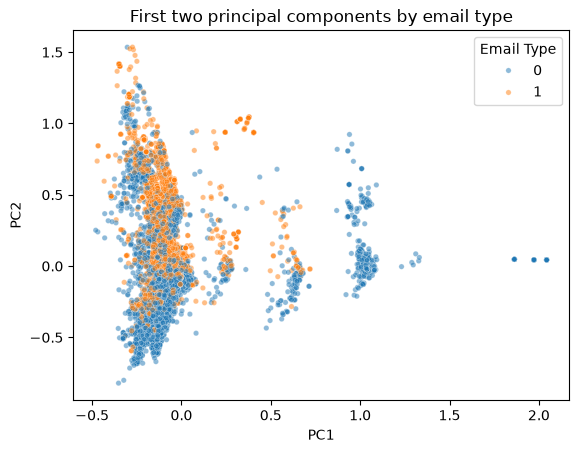

The scatter plot shows some separation between phishing and legitimate emails along the first two principal components. There are distinct vertical stripes along PC1, suggesting that many emails have similar values for this component. For PC1 values above approximately 1, most or all emails appear to be legitimate, regardless of PC2. At lower PC1 values, emails with PC2 above approximately 0 appear more likely to be phishing scams, while emails below 0 appear more likely to be legitimate. However, the two classes are not perfectly separated, so the first two principal components do not completely distinguish phishing emails from legitimate ones.


In [10]:
print('Q3')

pca = PCA(n_components=2)
Z = pca.fit_transform(X)

plot_df = pd.DataFrame(Z, columns=['PC1', 'PC2'], index=X.index)
plot_df['Email Type'] = y

sns.scatterplot(data=plot_df, x='PC1', y='PC2', hue='Email Type', alpha=0.5, s=15)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('First two principal components by email type')
plt.show()

print('The scatter plot shows some separation between phishing and legitimate emails along the first two principal components. There are distinct vertical stripes along PC1, suggesting that many emails have similar values for this component. For PC1 values above approximately 1, most or all emails appear to be legitimate, regardless of PC2. At lower PC1 values, emails with PC2 above approximately 0 appear more likely to be phishing scams, while emails below 0 appear more likely to be legitimate. However, the two classes are not perfectly separated, so the first two principal components do not completely distinguish phishing emails from legitimate ones.')

In [11]:
print('Q4')

pca = PCA(n_components=2610)
Z_train = pca.fit_transform(X_train)
Z_test = pca.transform(X_test)

model_pca = LinearRegression()
model_pca.fit(Z_train, y_train)

print('PCA Regression Training R^2:', model_pca.score(Z_train, y_train))
print('PCA Regression Test R^2:', model_pca.score(Z_test, y_test))

print('The results are very similar to the linear regression. The linear regression has a training R^2 of 0.769 and test R^2 of 0.656 while the PCA regression has a training R^2 of 0.768 and test R^2 of 0.658. This makes sense since using 2610 components is almost all of the 2711 tokens, so it retains almost all the variation of the total dataset.')

Q4
PCA Regression Training R^2: 0.7678719293227674
PCA Regression Test R^2: 0.6584780718049499
The results are very similar to the linear regression. The linear regression has a training R^2 of 0.769 and test R^2 of 0.656 while the PCA regression has a training R^2 of 0.768 and test R^2 of 0.658. This makes sense since using 2610 components is almost all of the 2711 tokens, so it retains almost all the variation of the total dataset.


In [12]:
print('Q5')

print('PCA is useful for high-dimensional regression because it reduces the number of predictors while retaining as much of the variation in the original data as possible. This can reduce computational costs, help address multicollinearity between correlated features, and potentially reduce overfitting. The resulting model uses fewer predictors, although the principal components can be harder to interpret than the original words.')

Q5
PCA is useful for high-dimensional regression because it reduces the number of predictors while retaining as much of the variation in the original data as possible. This can reduce computational costs, help address multicollinearity between correlated features, and potentially reduce overfitting. The resulting model uses fewer predictors, although the principal components can be harder to interpret than the original words.


### *Reflection on AI assistance
In your own words without generative AI.

AI was really helpful in this assignment at refining conclusions and better explaining concepts or interpretations in them. The AI was good at taking the ideas I had a start to and expanding on them to be more grammatically and technically clear. Especially for the PCA interpretations, I had misunderstood them a little bit, but the AI was able to clear it up and phrase it in a way that made sense. The AI did not really make technical mistakes but it had a suggestion that was not very useful since it implemented the same thing. The AI was limited to only refining the conclusions since it was not running the processing the data by itself but only going off what I gave it and assuming it was correct. I made sure to rerun everything still to make sure the results ran and the conclusions still had the same main idea I initially concluded.